In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

test = pd.read_csv("data/clean/test_scored.csv")
cutoffs = range(int(test["score"].min()), int(test["score"].max()) + 1)

scenarios = {
    "Base":             (1.0, 0.60),
    "Mild recession":   (1.5, 0.65),
    "Severe recession": (2.0, 0.75),
}

def profit_at(c, mult, lgd):
    a = test[test["score"] >= c]
    bads = a["default_2yrs"].sum() * mult
    goods = len(a) - bads
    return (goods * 400 - bads * 5000 * lgd) / len(test) * 10000

In [2]:
rows = []
for name, (mult, lgd) in scenarios.items():
    curve = [(profit_at(c, mult, lgd), c) for c in cutoffs]
    best_profit, best_cut = max(curve)
    p548 = profit_at(548, mult, lgd)
    rows.append({
        "scenario": name,
        "bad_rate_at_548": round(test.loc[test["score"] >= 548, "default_2yrs"].mean() * mult * 100, 1),
        "profit_at_548": round(p548),
        "approve_all_profit": round(profit_at(cutoffs[0], mult, lgd)),
        "best_cutoff": best_cut,
        "approval_at_best": round((test["score"] >= best_cut).mean() * 100, 1),
        "profit_at_best": round(best_profit),
        "cost_of_not_adjusting": round(best_profit - p548)})

stress = pd.DataFrame(rows)
stress.to_csv("outputs/stress_test.csv", index=False)
stress

,scenario,bad_rate_at_548,profit_at_548,approve_all_profit,best_cutoff,approval_at_best,profit_at_best,cost_of_not_adjusting
0,Base,3.0,2595022,1727289,548,87.1,2595022,0
1,Mild recession,4.5,2053678,340267,562,77.4,2180683,127006
2,Severe recession,6.0,1316667,-1548089,573,68.6,1764933,448267


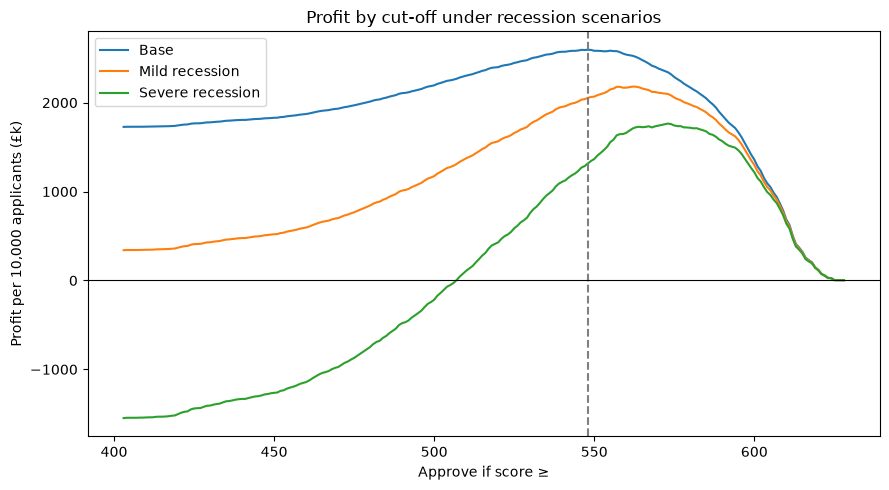

In [3]:
plt.figure(figsize=(9, 5))
for name, (mult, lgd) in scenarios.items():
    plt.plot(list(cutoffs), [profit_at(c, mult, lgd) / 1000 for c in cutoffs], label=name)
plt.axvline(548, linestyle="--", color="grey")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Profit by cut-off under recession scenarios")
plt.xlabel("Approve if score ≥")
plt.ylabel("Profit per 10,000 applicants (£k)")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/stress_test.png", dpi=150)
plt.show()